In [1]:
import seaborn as sns
import pandas as pd
import numpy as np

# Load the dataset
df = sns.load_dataset("taxis")

# Display the first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [2]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [3]:
missing = df.isnull().sum()

print(missing[missing > 0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [4]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 186


In [5]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns

C:\Users\DEVIKA\AppData\Local\Temp\ipykernel_34380\2569520227.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns


In [7]:
for col in num_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

In [8]:
for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
df = df.dropna(subset=["pickup", "dropoff"])

In [10]:
print(df.isnull().sum())
print("Total missing values after treatment:", df.isnull().sum().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Total missing values after treatment: 0


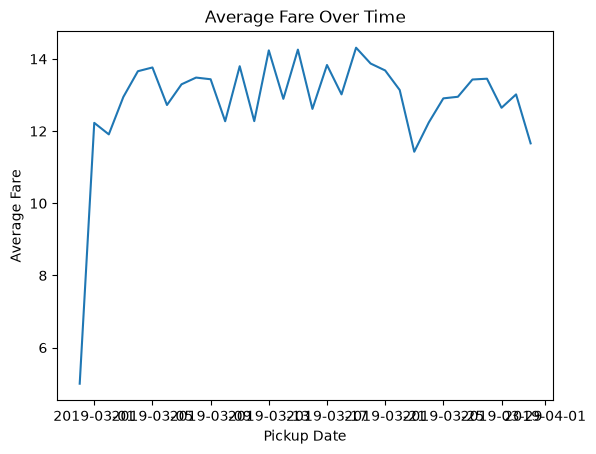

In [13]:
df["pickup"] = pd.to_datetime(df["pickup"])

df.groupby(df["pickup"].dt.date)["fare"].mean().plot(kind="line")

plt.xlabel("Pickup Date")
plt.ylabel("Average Fare")
plt.title("Average Fare Over Time")
plt.show()

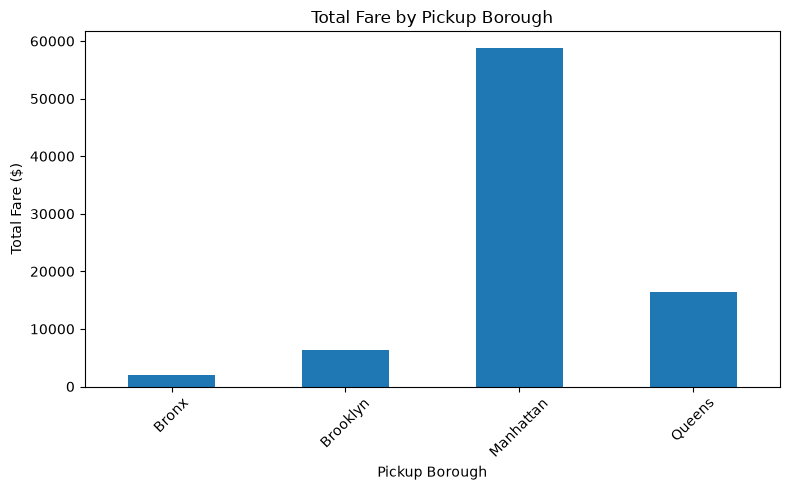

In [14]:

borough_fare = df.groupby("pickup_borough")["fare"].sum()


borough_fare.plot(kind="bar", figsize=(8, 5))

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.title("Total Fare by Pickup Borough")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

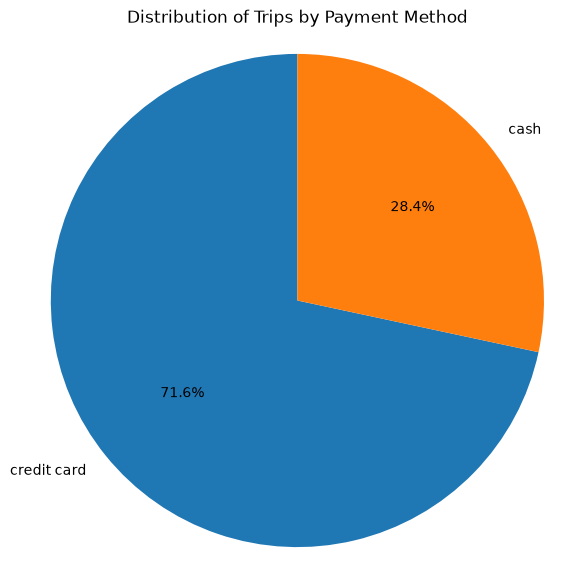

In [15]:

payment_counts = df["payment"].value_counts()


plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.axis("equal")
plt.show()

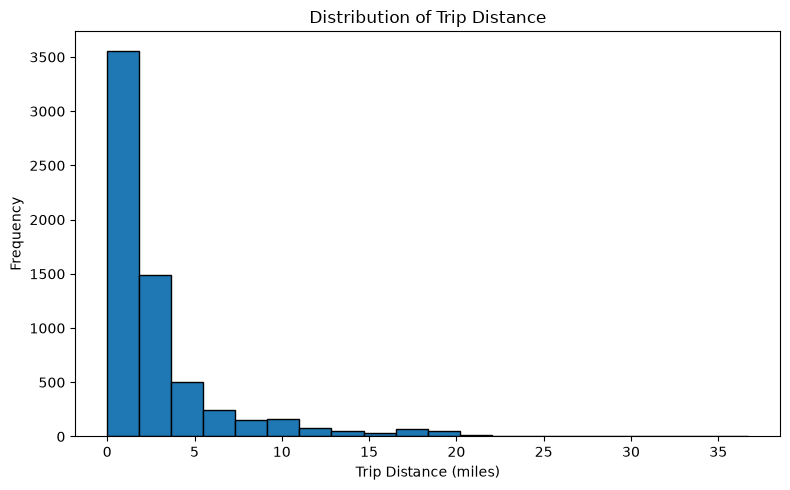

In [16]:

plt.figure(figsize=(8, 5))
plt.hist(df["distance"].dropna(), bins=20, edgecolor="black")

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Distance")
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

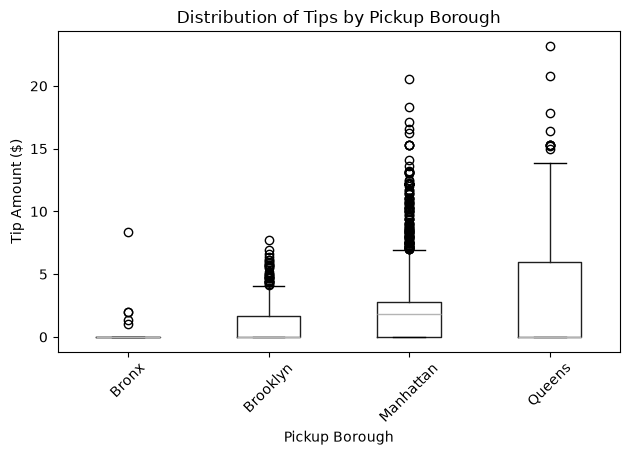

In [17]:
6
box_data = df.dropna(subset=["pickup_borough", "tip"])


plt.figure(figsize=(9, 5))
box_data.boxplot(
    column="tip",
    by="pickup_borough",
    grid=False
)

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

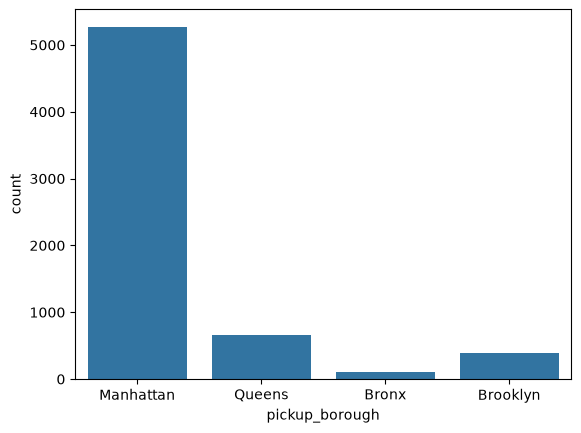

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

sns.countplot(data=df, x="pickup_borough")
plt.show()

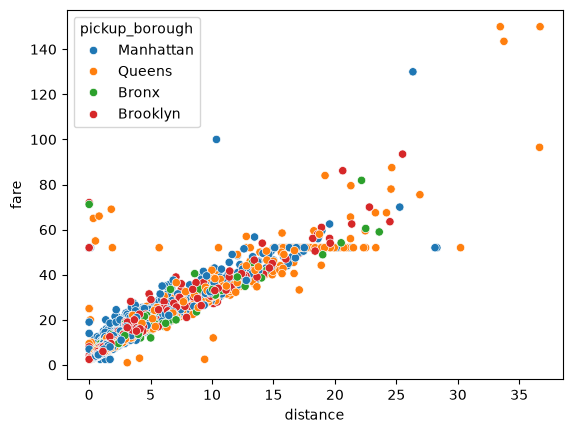

In [19]:
sns.scatterplot(data=df, x="distance", y="fare",
                hue="pickup_borough")
plt.show()

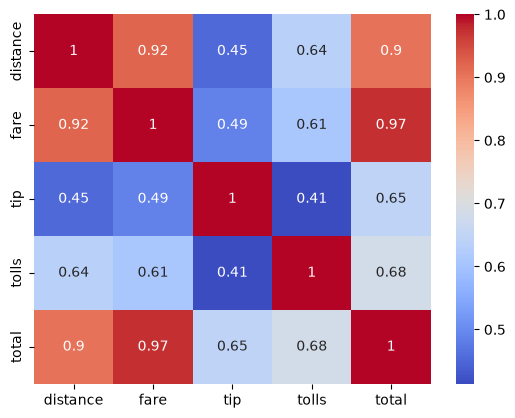

In [20]:
cols = ["distance", "fare", "tip", "tolls", "total"]

sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.show()

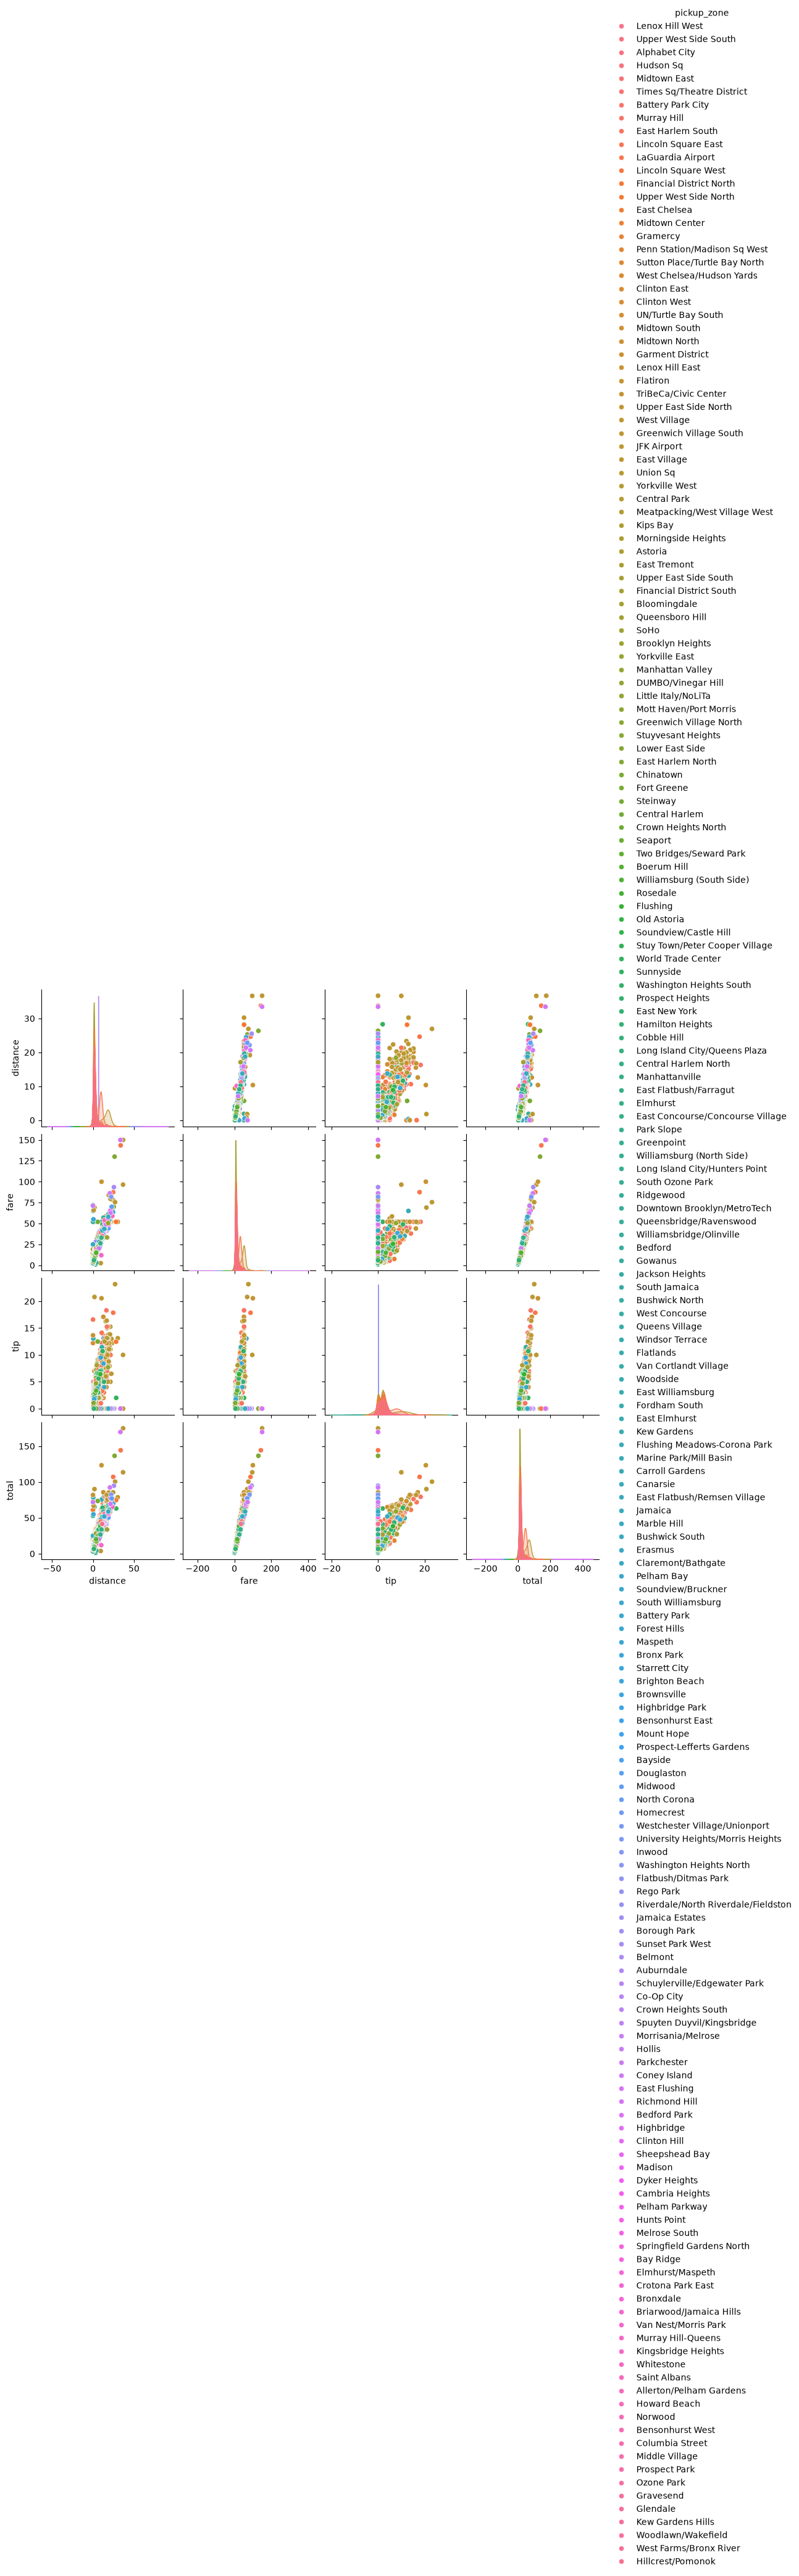

In [21]:
sns.pairplot(data=df, vars=["distance", "fare", "tip", "total"],
             hue="pickup_zone")
plt.show()

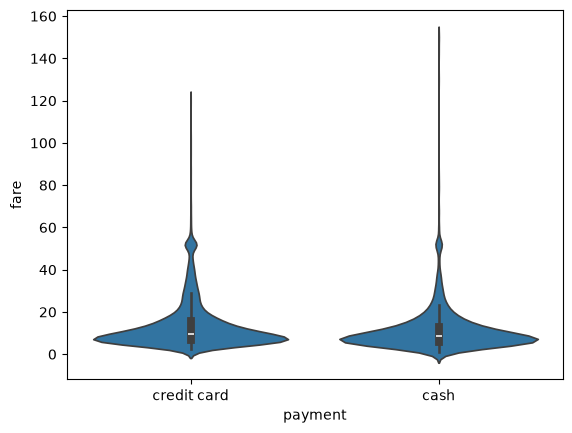

In [22]:
sns.violinplot(data=df, x="payment", y="fare")
plt.show()